# Unit 7: Mengkonstruksi Data
**Kode unit:** J.62DMI00.009.1 · SKKNI No. 299 Tahun 2020 · Proyek: *Prediksi Arah Harian IHSG*

**Tujuan unit ini:** membuat fitur dan target, lalu membagi data latih dan data uji.

In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110

In [2]:
df = pd.read_csv('../data/processed/data_bersih.csv', parse_dates=['Date'])
kolom = ['IHSG', 'SP500', 'VIX', 'OIL', 'GOLD', 'USDIDR']

## 1. Membuat fitur
Setiap fitur adalah **perubahan harian (%)** suatu variabel pada hari ini. Persentase perubahan dipakai (bukan harga)
karena harga terus naik dari tahun ke tahun, sedangkan persentase perubahan dapat dibandingkan antarwaktu.

In [3]:
data = pd.DataFrame({'Date': df['Date']})
for k in kolom:
    data[k.lower() + '_chg'] = df[k].pct_change() * 100
FITUR = [k.lower() + '_chg' for k in kolom]
print('Fitur:', FITUR)

Fitur: ['ihsg_chg', 'sp500_chg', 'vix_chg', 'oil_chg', 'gold_chg', 'usdidr_chg']


## 2. Membuat target

In [4]:
ihsg_besok = df['IHSG'].shift(-1)
data['target'] = (ihsg_besok > df['IHSG']).astype(int)

# baris pertama tidak punya perubahan, baris terakhir belum punya target
data = data.iloc[1:-1].reset_index(drop=True)
print('Jumlah data:', len(data))
data.head()

Jumlah data: 3974


,Date,ihsg_chg,sp500_chg,vix_chg,oil_chg,gold_chg,usdidr_chg,target
0,2010-01-05,1.159570,0.311568,-3.443116,0.318973,0.035790,-0.630059,0
1,2010-01-06,-0.076002,0.054552,-0.981915,1.724353,1.591991,-0.936042,0
2,2010-01-07,-0.630047,0.400120,-0.521923,-0.625146,-0.246505,0.590148,1
3,2010-01-08,1.062091,0.288173,-4.879330,0.108875,0.450091,-0.644916,1
4,2010-01-11,0.682151,0.174676,-3.199117,-0.277950,1.098225,-0.701212,1


## 3. Membagi data latih dan data uji (urut waktu, tanpa diacak)

In [5]:
batas = int(len(data) * 0.8)
latih = data.iloc[:batas]
uji = data.iloc[batas:]

print(f"Data latih: {len(latih)} hari ({latih['Date'].min().date()} s.d. {latih['Date'].max().date()}), naik {latih['target'].mean():.1%}")
print(f"Data uji  : {len(uji)} hari ({uji['Date'].min().date()} s.d. {uji['Date'].max().date()}), naik {uji['target'].mean():.1%}")

latih.to_csv('../data/processed/latih.csv', index=False)
uji.to_csv('../data/processed/uji.csv', index=False)

Data latih: 3179 hari (2010-01-05 s.d. 2023-01-11), naik 54.5%
Data uji  : 795 hari (2023-01-12 s.d. 2026-05-26), naik 52.8%


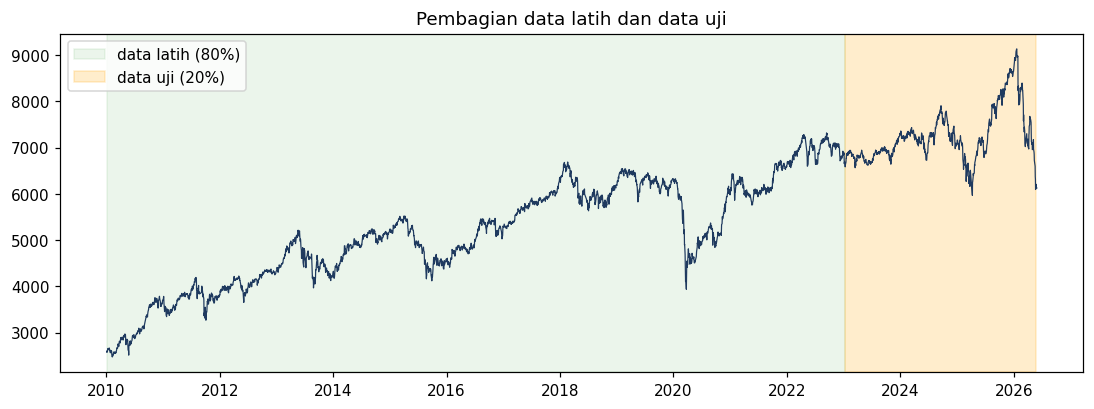

In [6]:
plt.figure(figsize=(12, 4))
plt.plot(df['Date'], df['IHSG'], color='#1f3a5f', linewidth=0.8)
plt.axvspan(latih['Date'].min(), latih['Date'].max(), color='green', alpha=0.08, label='data latih (80%)')
plt.axvspan(uji['Date'].min(), uji['Date'].max(), color='orange', alpha=0.2, label='data uji (20%)')
plt.title('Pembagian data latih dan data uji')
plt.legend()
plt.savefig('../figures/07_pembagian_data.png', dpi=150, bbox_inches='tight')
plt.show()

## Kesimpulan
- **6 fitur**: perubahan harian IHSG, S&P 500, VIX, minyak, emas, dan USD/IDR.
- **Target**: 1 jika IHSG naik pada hari bursa berikutnya.
- Data dibagi **menurut waktu**: data lama untuk melatih, data terbaru untuk menguji.